In [1]:
# Some basic setup:
# Setup detectron2 logger
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

# import some common libraries
import os
import numpy as np
import cv2
import random
import matplotlib.pyplot as plt

# import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog

In [2]:
# download sample image using wget
!wget http://images.cocodataset.org/val2017/000000439715.jpg -O input.jpg

--2026-09-22 13:24:03--  http://images.cocodataset.org/val2017/000000439715.jpg
Resolving images.cocodataset.org (images.cocodataset.org)... 54.231.198.33, 16.15.229.9, 16.182.101.137, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|54.231.198.33|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 209222 (204K) [image/jpeg]
Saving to: ‘input.jpg’

input.jpg           100%[===================>] 204.32K  --.-KB/s    in 0.01s   

2026-09-22 13:24:03 (19.0 MB/s) - ‘input.jpg’ saved [209222/209222]



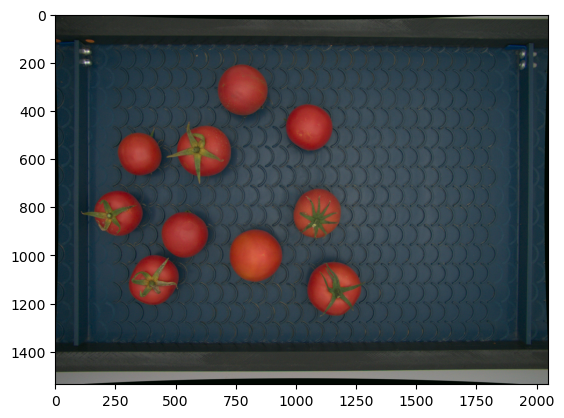

In [3]:
# Load BGR test-image using opencv
img = cv2.imread("tomato_calyx.png")

# Show the RGB image using matplotlib imshow
plt.imshow(img[...,::-1]);

In [4]:
mrcnn_model = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

In [5]:
# Create Model Configuration object
cfg = get_cfg()

# Add model architecture config, which we set earlier
cfg.merge_from_file(model_zoo.get_config_file(mrcnn_model))

# Load the model weights that we set earlier
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(mrcnn_model)

# Set threshold for this model
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.7  

# Create Predictor for inference based on configuration set
predictor = DefaultPredictor(cfg)

[09/22 13:24:05 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x/137849600/model_final_f10217.pkl ...


In [6]:
# Predict the Instance segmentation of input image using predictor
outputs = predictor(img)

/opt/conda/lib/python3.11/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [7]:
# You can examine the output structure if you wish
outputs

{'instances': Instances(num_instances=6, image_height=1536, image_width=2048, fields=[pred_boxes: Boxes(tensor([[1046.3860, 1028.4591, 1273.8159, 1252.6826],
         [ 956.7374,  372.7608, 1152.9097,  562.4199],
         [ 262.3225,  497.9517,  441.5981,  670.7363],
         [ 674.3795,  210.6675,  883.9020,  429.1355],
         [ 724.8582,  890.6335,  945.9813, 1115.7996],
         [ 304.6995,  997.5956,  512.7737, 1208.6151]], device='cuda:0')), scores: tensor([0.9730, 0.9346, 0.9334, 0.7420, 0.7418, 0.7127], device='cuda:0'), pred_classes: tensor([32, 32, 32, 32, 32, 32], device='cuda:0'), pred_masks: tensor([[[False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          ...,
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False]],
 
         [

In [8]:
# Print how many object detected
print('Object Detected: ', len(outputs['instances'].scores))

# Print the Classification class
print('Classification class: ', outputs['instances'].pred_classes.tolist())

# Print bounding box for each predicted object
print('Bounding Box: \n', outputs['instances'].pred_boxes)

Object Detected:  6
Classification class:  [32, 32, 32, 32, 32, 32]
Bounding Box: 
 Boxes(tensor([[1046.3860, 1028.4591, 1273.8159, 1252.6826],
        [ 956.7374,  372.7608, 1152.9097,  562.4199],
        [ 262.3225,  497.9517,  441.5981,  670.7363],
        [ 674.3795,  210.6675,  883.9020,  429.1355],
        [ 724.8582,  890.6335,  945.9813, 1115.7996],
        [ 304.6995,  997.5956,  512.7737, 1208.6151]], device='cuda:0'))


In [9]:
# Create metadata namespace which refer to the Train Dataset in the configuration files
metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])

# Now we can check for example class `17` is what class
print('Class 17 is ', metadata.thing_classes[17])

# Now we can check for example class `0` is what class
print('Class 0 is ', metadata.thing_classes[0])

Class 17 is  horse
Class 0 is  person


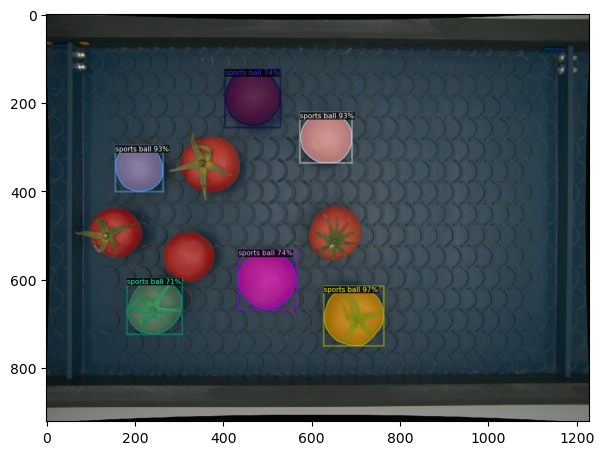

In [10]:
# create viz object from `Visualizer`
vis = Visualizer(img_rgb=img[...,::-1], metadata=metadata, scale=0.6) # Scale is the text size

# Draw the prediction using `.draw_instance_prediction()` function
out = vis.draw_instance_predictions(outputs['instances'].to('cpu'))

# Show the image segmentation result
plt.figure(figsize=(7,10))
plt.imshow(out.get_image());

## Train a custom dataset

In [15]:
#Train a custom dataset
# download & decompress the data (uncomment for download)
!wget https://github.com/Tony607/detectron2_instance_segmentation_demo/releases/download/V0.1/data.zip
!unzip -o data.zip 

--2026-09-22 13:38:49--  https://github.com/Tony607/detectron2_instance_segmentation_demo/releases/download/V0.1/data.zip
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/214809806/96896a00-edf1-11e9-9276-03497ac88ccb?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-09-22T14%3A35%3A13Z&rscd=attachment%3B+filename%3Ddata.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-09-22T13%3A34%3A17Z&ske=2026-09-22T14%3A35%3A13Z&sks=b&skv=2018-11-09&sig=mnfCoHWR42ho0C61S8KMmNM63H7%2F02ClgrcnWfhrScQ%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MDA4NDYyOSwibmJmIjoxNzkwMDg0MzI5LCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZH

In [16]:
!ls data
!tree data

images	trainval.json
/bin/bash: line 1: tree: command not found


In [14]:
#Register the dataset
# Import `register_coco_instances()` function
from detectron2.data.datasets import register_coco_instances

# Register our coco dataset format by giving the directory folder
register_coco_instances("fruits_nuts", {}, "./data/trainval.json", "./data/images")

In [17]:
#After the coco format of the dataset is registered, now we can create the dataset & metadata catalog
# Import `MetadataCatalog` and `DatasetCatalog`
from detectron2.data import MetadataCatalog, DatasetCatalog

# Create Metadata & Dataset Catalog
fruits_nuts_metadata = MetadataCatalog.get("fruits_nuts")
dataset_dicts = DatasetCatalog.get("fruits_nuts")

[09/22 13:39:00 d2.data.datasets.coco]: Loaded 18 images in COCO format from ./data/trainval.json


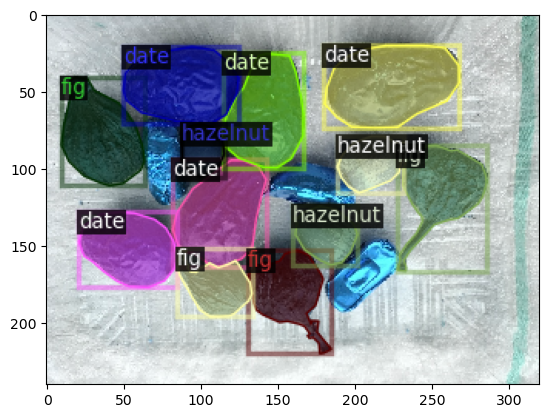

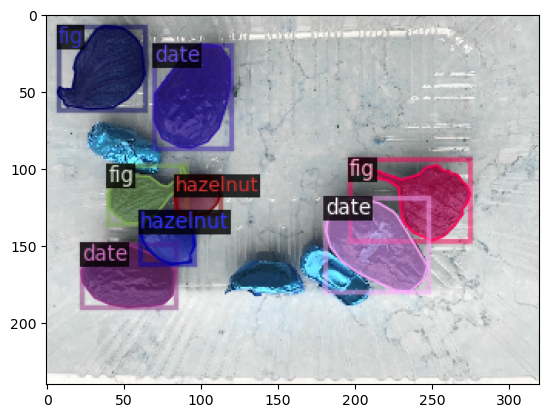

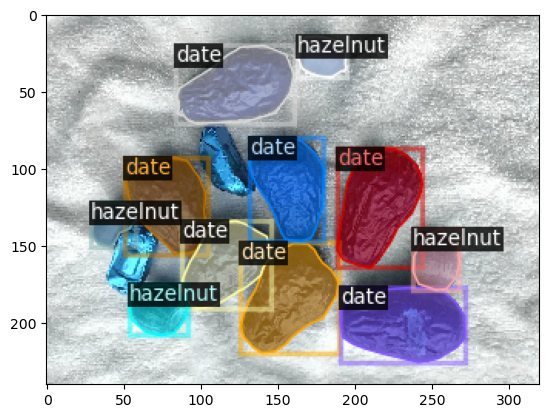

In [18]:
#let's visualize the annotations of randomly selected samples in the dataset:
from detectron2.utils.visualizer import Visualizer
import random


for d in random.sample(dataset_dicts, 3):
    img = cv2.imread(d["file_name"])
    visualizer = Visualizer(img[:, :, ::-1], 
                            metadata=fruits_nuts_metadata, 
                            scale=0.4)
    vis = visualizer.draw_dataset_dict(d)
    plt.imshow(vis.get_image()[:, :, ::-1])
    plt.show()

In [19]:
#Now, let's fine tune a coco-pretrained R-50 FPN Mask R-CNN Model to our dataset.
# Import DefaultTrainer from engine & config function
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg

# Mask R-CNN Model used
mrcnn_model = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

# Set configuration
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(mrcnn_model))
cfg.DATASETS.TRAIN = ("fruits_nuts",)
cfg.DATASETS.TEST = ()   # no metrics implemented for this dataset
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(mrcnn_model) # initialize from model zoo
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.02
cfg.SOLVER.MAX_ITER = 300    # 300 iterations seems good enough, but you can certainly train longer
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128   # faster, and good enough for this toy dataset
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 3  # 3 classes (data, fig, hazelnut)

# Create output folder & Train
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[09/22 13:43:37 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (4, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (4,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (12, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (12,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (3, 256, 1, 1) 

[09/22 13:43:37 d2.engine.train_loop]: Starting training from iteration 0
[09/22 13:43:46 d2.utils.events]:  eta: 0:01:49  iter: 19  total_loss: 2.159  loss_cls: 0.7206  loss_box_reg: 0.8804  loss_mask: 0.5391  loss_rpn_cls: 0.00912  loss_rpn_loc: 0.01646    time: 0.3992  last_time: 0.4391  data_time: 0.0085  last_data_time: 0.0030   lr: 0.0012854  max_mem: 2431M
[09/22 13:43:54 d2.utils.events]:  eta: 0:01:41  iter: 39  total_loss: 0.9651  loss_cls: 0.3258  loss_box_reg: 0.5423  loss_mask: 0.09151  loss_rpn_cls: 0.001552  loss_rpn_loc: 0.02384    time: 0.3914  last_time: 0.4368  data_time: 0.0032  last_data_time: 0.0031   lr: 0.0026174  max_mem: 2431M
[09/22 13:44:02 d2.utils.events]:  eta: 0:01:33  iter: 59  total_loss: 0.451  loss_cls: 0.09948  loss_box_reg: 0.253  loss_mask: 0.06846  loss_rpn_cls: 0.00155  loss_rpn_loc: 0.02701    time: 0.3955  last_time: 0.3568  data_time: 0.0034  last_data_time: 0.0035   lr: 0.0039494  max_mem: 2432M
[09/22 13:44:10 d2.utils.events]:  eta: 0:01:2

[09/22 13:52:17 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output/model_final.pth ...


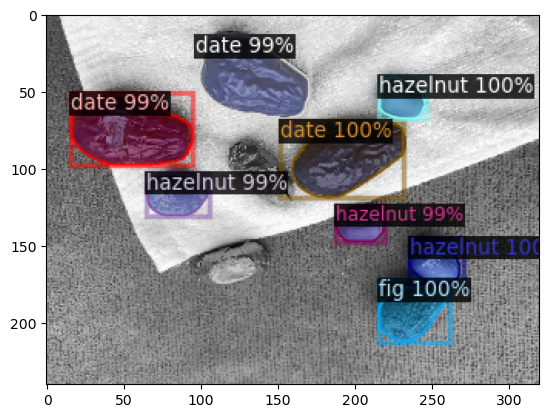

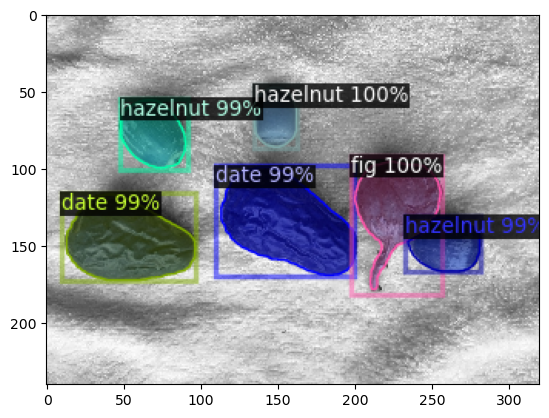

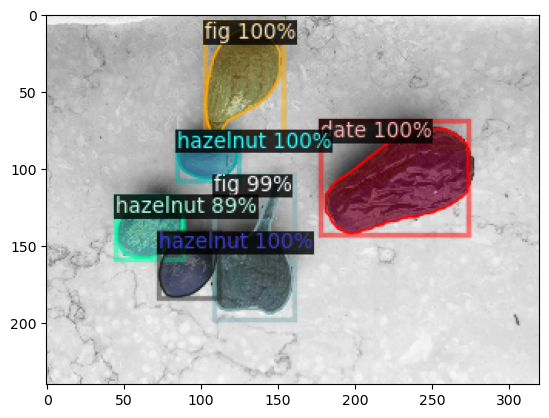

In [20]:
#Inference & Evaluation using trained model
# Load model weights
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, 'model_final.pth')
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.7   # set the testing threshold for this model
cfg.DATASETS.TEST = ("fruits_nuts", )

# Create Predictor for inference
predictor = DefaultPredictor(cfg)

#Now we will use predictor to inference and visualize it's output
from detectron2.utils.visualizer import ColorMode

for d in random.sample(dataset_dicts, 3):    
    im = cv2.imread(d["file_name"])
    outputs = predictor(im)
    v = Visualizer(im[:, :, ::-1],
                   metadata=fruits_nuts_metadata, 
                   scale=0.4,
                   # remove the colors of unsegmented pixels
                   instance_mode=ColorMode.IMAGE_BW   )
    v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    plt.imshow(v.get_image()[:, :, ::-1])
    plt.show()